# INKAR-Daten erkunden

Dieses Notebook führt anhand ausgewählter Regionalindikatoren durch eine explorative Datenanalyse (EDA). Wir laden die vorbereiteten INKAR-Daten, verschaffen uns einen Überblick über Räume und Indikatoren, wählen Beobachtungen aus und bereiten sie für Zeitreihendiagramme auf.

**Lernziele**
- den tabellarischen Aufbau und wichtige Variablen eines Datensatzes beschreiben,
- Daten nach Raumebene, Indikator und Jahr filtern,
- Lang- und Breitformat unterscheiden und passend einsetzen,
- Zeitreihen statisch und interaktiv vergleichen.

Führe die Zellen der Reihe nach aus. Jede Codezelle baut auf Variablen auf, die in den vorherigen Zellen angelegt wurden.

### Vorbereitung

Die Imports machen die Werkzeuge für Tabellen (`pandas`), Dateipfade (`pathlib`) und Typangaben verfügbar. Die nächste Codezelle enthält eine optionale Installationsanweisung: Nur wenn ein Import fehlt, kannst du das Kommentarzeichen vor `%pip` entfernen und die Zelle ausführen. Starte danach bei Bedarf den Kernel neu.

In [30]:
# Optional: Installation ausführen, falls ein benoetigtes Paket fehlt.
%pip install "pandas" "pyarrow" "plotnine" "plotly"

Note: you may need to restart the kernel to use updated packages.


In [31]:
from collections.abc import Iterable
from pathlib import Path
from typing import Optional, Tuple, Union  # noqa: UP035
import pandas as pd
import plotly
import plotly.graph_objects as go

## Datensatz laden

Die Parquet-Datei enthält die für dieses Beispiel vorbereiteten INKAR-Beobachtungen. `Path` hilft dabei, Dateipfade plattformuebergreifend zusammenzusetzen. Die Prüfungen brechen mit einer verständlichen Fehlermeldung ab, falls die Datei an keinem der erwarteten Orte liegt. `head()` zeigt anschließend die ersten Zeilen; die ausgegebene Form nennt Zeilen- und Spaltenzahl.

In [32]:
# EINTRAGEN -> Euer Pfad zur Parquet-Datei
path = Path("exam/data/inkar_bayern.parquet")

In [33]:
# Laden der Parquet-Datei
if not path.is_file():
    alternatives = [
        Path("data/inkar_bayern.parquet"),
        Path("../data/inkar_bayern.parquet"),
        Path("../../exam/data/inkar_bayern.parquet"),
    ]
    path = next((candidate for candidate in alternatives if candidate.is_file()), None)

if path is None or not path.is_file():
    raise FileNotFoundError(
        "Parquet-Datei nicht gefunden. Prüfe den Projektpfad exam/data/inkar_bayern.parquet."
    )

bayern_df = pd.read_parquet(path, engine="pyarrow")
print(f"Parquet-Datei erfolgreich geladen: {path}")

Parquet-Datei erfolgreich geladen: ..\data\inkar_bayern.parquet


In [34]:
print(f"{bayern_df.shape[0]:,} Zeilen und {bayern_df.shape[1]} Spalten")
print(bayern_df.columns)
display(bayern_df.head())

850,220 Zeilen und 10 Spalten
Index(['Kennziffer', 'Name', 'Nordbayern', 'Raumbezug', 'Zeitbezug',
       'Indikator', 'Kuerzel', 'Bereich', 'ID', 'Wert'],
      dtype='object')


,Kennziffer,Name,Nordbayern,Raumbezug,Zeitbezug,Indikator,Kuerzel,Bereich,ID,Wert
0,09161000,Ingolstadt,False,Kreise,2023,Bevölkerung,a_bb_4G,EU,<NA>,100.0
1,09161000,Ingolstadt,False,Kreise,2023,Bildung,a_bb_4G,EU,<NA>,100.0
2,09161000,Ingolstadt,False,Kreise,2023,Gesundheit,a_bb_4G,EU,<NA>,100.0
3,09161000,Ingolstadt,False,Kreise,2023,Siedlungsstruktur,a_bb_4G,EU,<NA>,100.0
4,09161000,Ingolstadt,False,Kreise,2023,Verkehr,a_bb_4G,EU,<NA>,100.0


## Spalten und Indikatoren verstehen

`columns` gibt zunächst die Namen aller Variablen aus. Danach erstellen wir eine kompakte Indikatorenübersicht: Weil derselbe Indikator für viele Räume und Jahre vorkommt, entfernen wir doppelte Name-Kuerzel-Kombinationen. Die Sortierung erleichtert das Auffinden eines Merkmals.

In [35]:
indicators_info = (
    bayern_df[["Indikator", "Kuerzel"]]
    .drop_duplicates()
    .sort_values("Indikator")
    .reset_index(drop=True)
)

display(indicators_info)


,Indikator,Kuerzel
0,(SDG 1) Armut - Altersarmut,a_GSa
1,(SDG 1) Armut - Kinderarmut,q_newfBGu15_bev
2,(SDG 1) SGB II-/SGB XII-Quote,a_sgbII_III_bev
3,(SDG 10) Beschäftigungsquote - Ausländer,q_svw_ausl
4,(SDG 10) Einbürgerungen,q_ebuerg_aus
...,...,...
592,Öffentliche Bibliotheken,BibOEB
593,Öffentliche Bäder,OeffBad
594,Öffentliche Finanzen,a_bb_4G
595,Öffentliche Verwaltungsfunktion,a_bb_4G


## Räumliche Struktur erkunden

`Raumbezug` kennzeichnet die räumliche Ebene einer Beobachtung, zum Beispiel Regierungsbezirk oder Kreis. Die folgenden Tabellen helfen, die vorhandenen Ebenen und Gebietsnamen kennenzulernen, bevor wir Beobachtungen auswählen. `drop_duplicates()` sorgt dafür, dass jedes Gebiet nur einmal erscheint.

In [36]:
gebiete_info = (
    bayern_df[["Raumbezug"]]
    .drop_duplicates()
    .sort_values("Raumbezug")
    .reset_index(drop=True)
)

display(gebiete_info.head(15))


,Raumbezug
0,Bundesländer
1,Kreise
2,Regierungsbezirke


In [37]:
# Einmalige Liste der Regierungsbezirke für die räumliche Orientierung.
bezirke_info = (
    bayern_df[bayern_df["Raumbezug"].isin(["Regierungsbezirke"])]
    .sort_values(["Raumbezug", "Name"])
    .drop_duplicates(subset=["Raumbezug", "Name"])
    .reset_index(drop=True)
)

display(bezirke_info[['Kennziffer', 'Name', "Raumbezug"]].head(15))


,Kennziffer,Name,Raumbezug
0,095,Mittelfranken,Regierungsbezirke
1,092,Niederbayern,Regierungsbezirke
2,091,Oberbayern,Regierungsbezirke
3,094,Oberfranken,Regierungsbezirke
4,093,Oberpfalz,Regierungsbezirke
5,097,Schwaben,Regierungsbezirke
6,096,Unterfranken,Regierungsbezirke


In [38]:
kreise_info = (
    bayern_df[bayern_df["Raumbezug"].isin(["Kreise"])]
    .sort_values(["Raumbezug", "Name"])
    .drop_duplicates(subset=["Raumbezug", "Name"])
    .reset_index(drop=True)
)

display(kreise_info[['Kennziffer', 'Name', "Raumbezug"]])


,Kennziffer,Name,Raumbezug
0,09771000,Aichach-Friedberg,Kreise
1,09171000,Altötting,Kreise
2,09361000,Amberg,Kreise
3,09371000,Amberg-Sulzbach,Kreise
4,09571000,Ansbach,Kreise
...,...,...,...
91,09190000,Weilheim-Schongau,Kreise
92,09577000,Weißenburg-Gunzenhausen,Kreise
93,09479000,Wunsiedel i.Fichtelgebirge,Kreise
94,09679000,Würzburg,Kreise


### Filtermöglichkeit Nordbayern

Die Spalte `Nordbayern` markiert, ob ein Gebiet zu Nordbayern gehört. Mit `|` (ODER) kombinieren wir diese Auswahl mit den Beobachtungen auf Bundeslandebene. Die Klammern machen deutlich, welche Bedingungen zusammengehören. `.copy()` erstellt eine unabhängige Auswahl, die sich später gefahrlos weiterverarbeiten laesst.

In [39]:
nordbayern_df = bayern_df[
    (bayern_df["Raumbezug"] == "Bundesländer")
    | (bayern_df["Nordbayern"] == True)
].copy()

print(f"{len(nordbayern_df):,} von {len(bayern_df):,} Beobachtungen ausgewählt")


424,713 von 850,220 Beobachtungen ausgewählt


In [40]:
display(nordbayern_df.head())

,Kennziffer,Name,Nordbayern,Raumbezug,Zeitbezug,Indikator,Kuerzel,Bereich,ID,Wert
210,09361000,Amberg,True,Kreise,2023,Bevölkerung,a_bb_4G,EU,<NA>,100.0
211,09361000,Amberg,True,Kreise,2023,Bildung,a_bb_4G,EU,<NA>,100.0
212,09361000,Amberg,True,Kreise,2023,Gesundheit,a_bb_4G,EU,<NA>,100.0
213,09361000,Amberg,True,Kreise,2023,Siedlungsstruktur,a_bb_4G,EU,<NA>,100.0
214,09361000,Amberg,True,Kreise,2023,Verkehr,a_bb_4G,EU,<NA>,100.0


In [41]:
# Bezirke in nordbayern
nordbayern_bezirke_info = (nordbayern_df[nordbayern_df["Raumbezug"].isin(["Regierungsbezirke"])]
                           .sort_values(["Raumbezug", "Name"])
                           .drop_duplicates(subset=["Raumbezug", "Name"])
                           .reset_index(drop=True)
)

nordbayern_bezirke_info[['Kennziffer', 'Name', "Raumbezug"]]

,Kennziffer,Name,Raumbezug
0,095,Mittelfranken,Regierungsbezirke
1,094,Oberfranken,Regierungsbezirke
2,093,Oberpfalz,Regierungsbezirke
3,096,Unterfranken,Regierungsbezirke


## Vom Lang- ins Breitformat pivotieren: eine Hilfsfunktion

Im **Langformat** steht jede Kombination aus Gebiet, Indikator und Jahr in einer eigenen Zeile. Das ist praktisch zum Filtern und Zeichnen. Im **Breitformat** wird dagegen jede Kombination aus Jahr und Indikator zu einer eigenen Spalte.

Die Funktion unten filtert zuerst nach Raumebene und Indikatoren und wendet danach optional eine Jahresauswahl an. `time_filter` akzeptiert eine Jahresliste, ein Tupel mit eingeschlossenen Grenzen `(start, ende)` oder ein Python-`range` (dessen Ende ausgeschlossen ist). Beim Umformen gruppiert `pivot_table` nach Kennziffer, Name und Nordbayern-Kennzeichen. `aggfunc="first"` nimmt bei doppelten Kombinationen den ersten Wert; solche Duplikate sollten fachlich geprüft werden.

In [42]:
# Typen der drei unterstützten Formen für die Jahresauswahl.
YearList = Iterable[Union[int, str]]
YearRange = Tuple[Union[int, str], Union[int, str]]
TimeFilter = Union[YearList, YearRange, range]

def filter_and_pivot_inkar(
    df: pd.DataFrame,
    raumbezug: str,
    indikatoren: list[str],
    time_filter: Optional[TimeFilter] = None,
) -> pd.DataFrame:
    """
    Filtert nach Raumebene und Indikatoren und formt die Daten ins Breitformat um.

    Die Jahresauswahl kann eine Liste, ein Tupel mit eingeschlossenen Grenzen
    oder ein Python-range mit ausgeschlossenem Endjahr sein. Die erzeugten
    Spalten verbinden Jahr und Indikator, zum Beispiel ``2018_Arbeitslosenquote``.
    """

    # Zuerst nach der gewünschten Raumebene und Indikatorauswahl einschränken.
    df_filtered = df[df["Raumbezug"] == raumbezug].copy()
    df_filtered = df_filtered[df_filtered["Indikator"].isin(indikatoren)].copy()

    # Jahreswerte vereinheitlichen; nicht numerische Werte werden zu fehlenden Werten.
    z_raw = df_filtered["Zeitbezug"]
    z_year = pd.to_numeric(z_raw, errors="coerce").astype("Int64")  # Int64 erlaubt fehlende Jahreswerte.

    # Ein Tupel beschreibt einen inklusiven Jahresbereich; andere Iterables einzelne Jahre.
    if time_filter is not None:
        if isinstance(time_filter, tuple) and len(time_filter) == 2:
            start, end = time_filter
            start_i = int(pd.to_numeric(start, errors="raise"))
            end_i = int(pd.to_numeric(end, errors="raise"))
            df_filtered = df_filtered[(z_year >= start_i) & (z_year <= end_i)].copy()
        else:
            # Liste, anderes Iterable oder range: nur die genannten Jahre behalten.
            years = [int(pd.to_numeric(y, errors="raise")) for y in list(time_filter)]
            df_filtered = df_filtered[z_year.isin(years)].copy()

    # Jahreswerte als ganze Zahlen darstellen, damit die Spaltennamen einheitlich sind.
    df_filtered["Zeitbezug"] = pd.to_numeric(df_filtered["Zeitbezug"], errors="coerce") \
                                .astype("Int64") \
                                .astype(str) \
                                .where(pd.to_numeric(df_filtered["Zeitbezug"], errors="coerce").notna(),
                                       df_filtered["Zeitbezug"].astype(str))

    # Zeilen je Gebiet, Spalten je Jahr-Indikator-Kombination und Werte aus "Wert".
    df_pivoted = df_filtered.pivot_table(
        index=["Kennziffer", "Name", "Nordbayern"],
        columns=["Zeitbezug", "Indikator"],
        values="Wert",
        aggfunc="first"  # Bei Duplikaten den ersten Wert verwenden; fachlich pruefen.
    )

    # Mehrstufige Spaltennamen zu lesbaren Namen wie "2018_Indikator" zusammenführen.
    df_pivoted.columns = [f"{zeitbezug}_{indikator}" for zeitbezug, indikator in df_pivoted.columns]
    df_pivoted = df_pivoted.reset_index()

    return df_pivoted


## Die Filtervarianten ausprobieren

Die drei Beispiele verwenden dieselben Kreise und Indikatoren, wählen die Jahre aber unterschiedlich aus. Eine Liste benennt einzelne Jahre, das Tupel schließt Start- und Endjahr ein, und `range` schließt das angegebene Endjahr aus. Die Vorschau macht sichtbar, wie die Spalten im Breitformat benannt sind.

In [43]:
indikatoren_liste = ["Angebotsmietpreise", "Arbeitslosenquote"]

# Beispiel 1: einzelne Jahre gezielt auswählen.
test1 = filter_and_pivot_inkar(
    nordbayern_df, "Kreise", indikatoren_liste, time_filter=[2018, 2020, 2022]
)

# Beispiel 2: beide Grenzen des Jahresbereichs sind eingeschlossen.
test2 = filter_and_pivot_inkar(
    nordbayern_df, "Kreise", indikatoren_liste, time_filter=(2015, 2022)
)

# Beispiel 3: range schließt das Endjahr aus; 2023 ist daher nicht enthalten.
test3 = filter_and_pivot_inkar(
    nordbayern_df, "Kreise", indikatoren_liste, time_filter=range(2020, 2023)
)

print("Einzeljahre:")
display(test1.head())

print("Inklusiver Jahresbereich:")
display(test2.head())

print("Python-range:")
display(test3.head())


Einzeljahre:


,Kennziffer,Name,Nordbayern,2018_Angebotsmietpreise,2018_Arbeitslosenquote,2020_Angebotsmietpreise,2020_Arbeitslosenquote,2022_Angebotsmietpreise,2022_Arbeitslosenquote
0,09361000,Amberg,True,7.0,4.4,8.0,5.35,9.0,4.22
1,09362000,"Regensburg, Stadt",True,11.0,3.19,11.0,4.38,12.0,3.81
2,09363000,Weiden i.d.OPf.,True,7.0,5.18,7.0,5.73,8.0,4.69
3,09371000,Amberg-Sulzbach,True,6.0,2.42,7.0,2.92,8.0,2.59
4,09372000,Cham,True,5.0,2.51,6.0,3.16,7.0,2.73


Inklusiver Jahresbereich:


,Kennziffer,Name,Nordbayern,2015_Angebotsmietpreise,2015_Arbeitslosenquote,2016_Angebotsmietpreise,2016_Arbeitslosenquote,2017_Angebotsmietpreise,2017_Arbeitslosenquote,2018_Angebotsmietpreise,2018_Arbeitslosenquote,2019_Angebotsmietpreise,2019_Arbeitslosenquote,2020_Angebotsmietpreise,2020_Arbeitslosenquote,2021_Angebotsmietpreise,2021_Arbeitslosenquote,2022_Angebotsmietpreise,2022_Arbeitslosenquote
0,09361000,Amberg,True,6.0,5.63,6.0,5.89,7.0,5.29,7.0,4.4,7.0,4.23,8.0,5.35,8.0,4.68,9.0,4.22
1,09362000,"Regensburg, Stadt",True,10.0,4.16,10.0,3.69,10.0,3.29,11.0,3.19,11.0,3.4,11.0,4.38,11.0,4.32,12.0,3.81
2,09363000,Weiden i.d.OPf.,True,6.0,7.17,6.0,6.61,6.0,6.11,7.0,5.18,7.0,5.15,7.0,5.73,7.0,5.12,8.0,4.69
3,09371000,Amberg-Sulzbach,True,5.0,2.91,5.0,2.91,6.0,2.71,6.0,2.42,7.0,2.33,7.0,2.92,7.0,2.73,8.0,2.59
4,09372000,Cham,True,5.0,3.02,5.0,3.07,5.0,2.69,5.0,2.51,6.0,2.51,6.0,3.16,7.0,2.85,7.0,2.73


Python-range:


,Kennziffer,Name,Nordbayern,2020_Angebotsmietpreise,2020_Arbeitslosenquote,2021_Angebotsmietpreise,2021_Arbeitslosenquote,2022_Angebotsmietpreise,2022_Arbeitslosenquote
0,09361000,Amberg,True,8.0,5.35,8.0,4.68,9.0,4.22
1,09362000,"Regensburg, Stadt",True,11.0,4.38,11.0,4.32,12.0,3.81
2,09363000,Weiden i.d.OPf.,True,7.0,5.73,7.0,5.12,8.0,4.69
3,09371000,Amberg-Sulzbach,True,7.0,2.92,7.0,2.73,8.0,2.59
4,09372000,Cham,True,6.0,3.16,7.0,2.85,7.0,2.73


## Im Langformat filtern

Für die Visualisierung bleiben die Spalten `Zeitbezug`, `Indikator` und `Wert` erhalten. Die Funktion filtert nach Raumebene und ausgewählten Indikatoren und kann zusätzlich auf einzelne Jahre oder einen Jahresbereich begrenzen. Im Gegensatz zur vorherigen Funktion pivotiert sie nicht: Das Ergebnis bleibt im Langformat.

In [44]:
def filter_inkar_panel(
    df: pd.DataFrame,
    raumbezug: str,
    indikatoren: list[str],
    time_filter: Optional[TimeFilter] = None,
) -> pd.DataFrame:
    """Filtert INKAR-Beobachtungen und erhält dabei das Langformat."""
    df_filtered = df[df["Raumbezug"] == raumbezug].copy()
    df_filtered = df_filtered[df_filtered["Indikator"].isin(indikatoren)].copy()

    years = pd.to_numeric(df_filtered["Zeitbezug"], errors="coerce").astype("Int64")
    if time_filter is not None:
        if isinstance(time_filter, tuple) and len(time_filter) == 2:
            start, end = time_filter
            start_year = int(pd.to_numeric(start, errors="raise"))
            end_year = int(pd.to_numeric(end, errors="raise"))
            if start_year > end_year:
                raise ValueError("Das Startjahr muss kleiner oder gleich dem Endjahr sein.")
            df_filtered = df_filtered[years.between(start_year, end_year)].copy()
        else:
            selected_years = [
                int(pd.to_numeric(year, errors="raise")) for year in time_filter
            ]
            df_filtered = df_filtered[years.isin(selected_years)].copy()

    return df_filtered


In [45]:
filtered_df = filter_inkar_panel(
    nordbayern_df,
    "Kreise",
    indikatoren_liste,
    time_filter=(2015, 2022),
)

print(f"{len(filtered_df):,} Beobachtungen nach dem Filtern")
display(filtered_df.head())


752 Beobachtungen nach dem Filtern


,Kennziffer,Name,Nordbayern,Raumbezug,Zeitbezug,Indikator,Kuerzel,Bereich,ID,Wert
92831,09361000,Amberg,True,Kreise,2015,Arbeitslosenquote,q_alo,LRB,14574,5.63
92832,09361000,Amberg,True,Kreise,2016,Arbeitslosenquote,q_alo,LRB,14574,5.89
92833,09361000,Amberg,True,Kreise,2017,Arbeitslosenquote,q_alo,LRB,14574,5.29
92834,09361000,Amberg,True,Kreise,2018,Arbeitslosenquote,q_alo,LRB,14574,4.4
92835,09361000,Amberg,True,Kreise,2019,Arbeitslosenquote,q_alo,LRB,14574,4.23


## Zeitreihen visualisieren

Wir betrachten beispielhaft bis zu drei Kreise und die ausgewählten Indikatoren für 2015 bis 2022. Die Facettengrafik zeigt für jeden Kreis ein eigenes Teilbild. So lassen sich zeitliche Verläufe nebeneinander vergleichen. `free_y` erlaubt jeder Facette eine eigene y-Achse; dadurch sind Trends innerhalb eines Kreises besser sichtbar, absolute Höhen zwischen Kreisen aber nicht direkt vergleichbar.

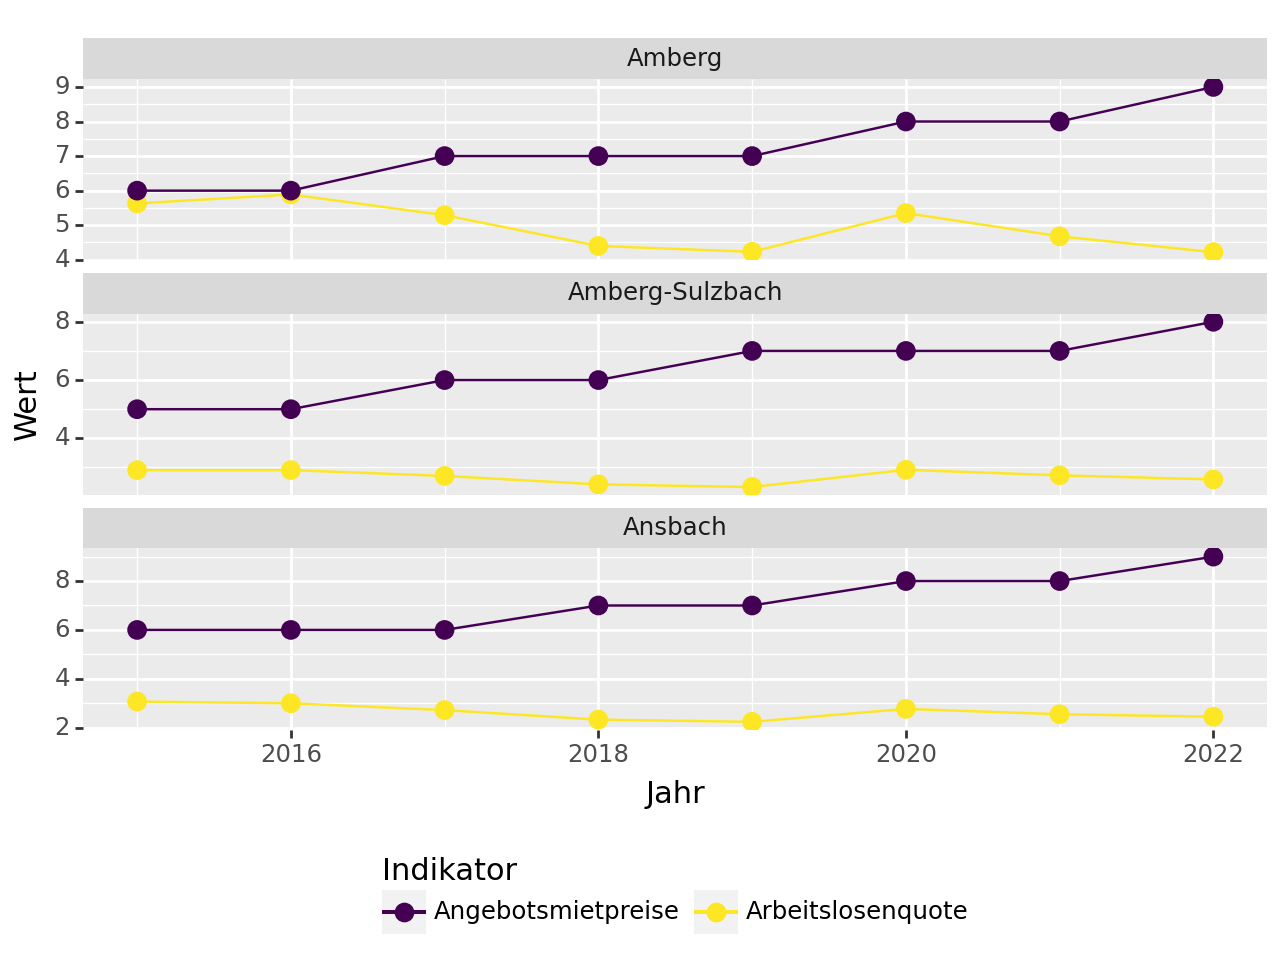

<Figure Size: (640 x 480)>

In [46]:
from IPython.display import display
from plotnine import ggplot, aes, geom_line, geom_point, facet_wrap, labs, theme

# Beispielauswahl begrenzen und nur vorhandene Indikatoren verwenden.
# Nur die benötigten Spalten für diese Gebiete und Indikatoren uebernehmen.
sampled_names = sorted(filtered_df["Name"].dropna().unique())[:3]
available_indikatoren = [
    name for name in indikatoren_liste
    if name in filtered_df["Indikator"].dropna().unique()
]

# Den Zeitbezug für die numerische x-Achse in ganze Zahlen umwandeln.
df_long = filtered_df.loc[
    filtered_df["Name"].isin(sampled_names)
    & filtered_df["Indikator"].isin(available_indikatoren),
    ["Name", "Zeitbezug", "Indikator", "Wert"],
].copy()

df_long["Name"] = pd.Categorical(
    df_long["Name"], categories=sampled_names, ordered=True
)
df_long["Indikator"] = pd.Categorical(
    df_long["Indikator"], categories=available_indikatoren, ordered=True
)
# Für die x-Achse wird der Zeitbezug als Zahl benoetigt.
df_long["Zeitbezug"] = pd.to_numeric(df_long["Zeitbezug"], errors="raise").astype(int)

# Figur erstellen: Linienplot mit Punkten, Facetten pro Gebiet, freie y-Achsen.
graph = (
    ggplot(df_long, aes(x="Zeitbezug", y="Wert", color="Indikator", group="Indikator"))
    + geom_line()
    + geom_point(size=3)
    + facet_wrap("~Name", ncol=1, scales="free_y", drop=False)
    + labs(x="Jahr", y="Wert", color="Indikator")
    + theme(legend_position="bottom")
)

display(graph)

### Interaktive Auswahl mit Plotly

Die interaktive Grafik stellt die Zeitreihe für Kreis und Indikator dar. Über die Dropdown-Menüs lassen sich beide Merkmale auswählen; beim Überfahren eines Datenpunkts erscheinen Jahr und Wert. Die Grafik ergänzt den statischen Vergleich, ersetzt aber nicht die Prüfung der Achsenskalierung und Einheiten.

In [47]:
# Zeitbezug in Zahlen umwandeln und ungültige Jahre entfernen
df_all = filtered_df.copy()

df_all["Zeitbezug"] = pd.to_numeric(
    df_all["Zeitbezug"],
    errors="coerce"
).astype("Int64")

df_all = df_all.dropna(subset=["Zeitbezug"])


# Verfügbare Kreise und Indikatoren
kreise_list = sorted(df_all["Name"].unique())
indikatoren_all = sorted(df_all["Indikator"].unique())


# Amberg als initialen Kreis bestimmen

# Funktioniert auch bei Bezeichnungen wie
# "Amberg, kreisfreie Stadt"
amberg_candidates = [
    kreis for kreis in kreise_list
    if "Amberg" in kreis
]

if amberg_candidates:
    initial_kreis = amberg_candidates[0]
else:
    # Fallback, falls Amberg im Datensatz nicht vorkommt
    initial_kreis = kreise_list[0]


# Figure erstellen
fig = go.Figure()

# Informationen über die Traces separat speichern.
# Das ist zuverlässiger als startswith()/endswith() auf trace.name.
trace_info = []


# Zeitreihen hinzufügen
for kreis in kreise_list:

    for indikator in indikatoren_all:

        df_subset = (
            df_all[
                (df_all["Name"] == kreis)
                & (df_all["Indikator"] == indikator)
            ]
            .sort_values("Zeitbezug")
        )

        if df_subset.empty:
            continue

        # INITIAL:
        # Alle vorhandenen Indikatoren von Amberg anzeigen
        visible = kreis == initial_kreis

        fig.add_trace(
            go.Scatter(
                x=df_subset["Zeitbezug"],
                y=df_subset["Wert"],
                mode="lines+markers",

                # Im Diagramm reicht der Indikator als Legendenname,
                # weil ohnehin nur ein Kreis gleichzeitig dargestellt wird.
                name=indikator,

                visible=visible,

                hovertemplate=(
                    f"<b>{kreis}</b>"
                    "<br>Jahr: %{x}"
                    f"<br>{indikator}: %{{y:.2f}}"
                    "<extra></extra>"
                )
            )
        )

        trace_info.append({
            "kreis": kreis,
            "indikator": indikator
        })

# Dropdown 1: Kreis auswählen
kreis_buttons = []

for kreis in kreise_list:

    # Alle Indikatoren des ausgewählten Kreises sichtbar machen
    visibility = [
        info["kreis"] == kreis
        for info in trace_info
    ]

    kreis_buttons.append(
        dict(
            label=kreis,
            method="update",
            args=[
                {
                    "visible": visibility
                },
                {
                    "title": f"Indikatoren für {kreis}"
                }
            ]
        )
    )


# Dropdown 2: Indikator auswählen
indikator_buttons = []

# Zusätzlich ein Button "Alle Indikatoren"
indikator_buttons.append(
    dict(
        label="Alle Indikatoren",
        method="update",
        args=[
            # Initial bezieht sich dieser Button auf Amberg.
            {
                "visible": [
                    info["kreis"] == initial_kreis
                    for info in trace_info
                ]
            },
            {
                "title": f"Indikatoren für {initial_kreis}"
            }
        ]
    )
)

for indikator in indikatoren_all:

    visibility = [
        (
            info["kreis"] == initial_kreis
            and info["indikator"] == indikator
        )
        for info in trace_info
    ]

    indikator_buttons.append(
        dict(
            label=indikator,
            method="update",
            args=[
                {
                    "visible": visibility
                },
                {
                    "title": (
                        f"{initial_kreis} – {indikator}"
                    )
                }
            ]
        )
    )


# Layout
fig.update_layout(

    title=f"Indikatoren für {initial_kreis}",

    updatemenus=[

        # Kreis
        dict(
            buttons=kreis_buttons,
            direction="down",
            pad={"r": 10, "t": 10},
            showactive=True,

            x=0.0,
            xanchor="left",
            y=1.15,
            yanchor="top",

            bgcolor="lightgray",
            bordercolor="gray",
            font=dict(size=11)
        ),

        # Indikator
        dict(
            buttons=indikator_buttons,
            direction="down",
            pad={"r": 10, "t": 10},
            showactive=True,

            x=0.30,
            xanchor="left",
            y=1.15,
            yanchor="top",

            bgcolor="lightgray",
            bordercolor="gray",
            font=dict(size=11)
        )
    ],

    xaxis_title="Zeitbezug",
    yaxis_title="Wert",

    hovermode="x unified",

    height=600,

    margin=dict(t=150),

    legend=dict(
        title="Indikator"
    )
)

fig.show()